# 06 · Fase C — diagnóstico Grad-CAM: ¿dónde mira cada modelo y por qué falla en FaceSwap?
**Pregunta:** el detector entrenado en Deepfakes puntúa los FaceSwap como *más reales* que los originales (AUC < 0.5). ¿En qué regiones del recorte se apoya cada modelo (BCE vs. Focal γ = 2), cuando acierta y cuando falla?

**Hipótesis (escrita antes de correr):** el modelo se apoya en el contorno de la cara, donde está el borde de mezcla característico del generador Deepfakes. En FaceSwap ese artefacto es distinto, así que la evidencia de «falso» desaparece. Predicción: la masa de Grad-CAM en el anillo del **borde** es mayor en Deepfakes bien detectados que en los FaceSwap no detectados, y Focal no la desplaza hacia el interior. *Qué la refutaría:* masas de borde iguales entre aciertos y errores, o que Focal mueva la masa al interior sin mejorar el AUC.

**Método (D-10):** capa `block12`; selección emparejada desde las predicciones de BCE, por manipulación: 8 reales bien clasificadas, 8 falsas bien clasificadas, 8 falsos negativos y 8 falsos positivos (frame central de cada video). Mismos frames para BCE y Focal. Las métricas por región (interior / borde / fuera, aproximación geométrica del recorte 1.3×) se calculan además sobre **todos** los videos de test (2 frames por video).

**Inputs:** `ffpp-crops-g8` y el output del 04 (o del 03), que tiene `checkpoints/bce_s42.pt`, `checkpoints/focal_g2_s42.pt` y `preds_bce_s42.csv.gz`.

> **Licencia FF++:** Kaggle sube este notebook a GitHub con sus salidas. Ninguna celda muestra caras; las figuras con caras van a `privado/` (output privado de Kaggle). Tablas y gráficos numéricos sí se muestran. Lo que se publica son los IDs de los videos elegidos y las tablas numéricas.

In [1]:
# Kaggle: clona el repo (Internet = On). En local: usa la copia del repo desde notebooks/kaggle/
import os, sys, subprocess
from pathlib import Path
REPO_URL = "https://github.com/Gredith/DeepLearning-G8-TA_Repository.git"
ROOT = Path("/kaggle/working/repo") if Path("/kaggle").exists() else Path.cwd().parents[1]
if Path("/kaggle").exists() and not ROOT.exists():
    subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src" / "kaggle_e2"))
print("ROOT =", ROOT)

ROOT = /kaggle/working/repo


In [2]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from PIL import Image
import data as D, gradcam as G, teardown as T, analysis as A, kaggle_io as K, plotstyle as S; S.apply()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CROPS = K.find_crops()
OUT = K.WORK / "resultados"; OUT.mkdir(parents=True, exist_ok=True)
busca = [Path("/kaggle/input")] if Path("/kaggle/input").exists() else []
busca += [K.WORK, ROOT / "results"]
def encontrar(nombre):
    for b in busca:
        hit = sorted(Path(b).rglob(nombre)) if Path(b).exists() else []
        if hit: return hit[0]
    raise FileNotFoundError(f"No se encontró {nombre}: agregar el output del 04 (o del 03) como input")
RUNS = {"BCE (γ=0)": "bce_s42", "Focal (γ=2)": "focal_g2_s42"}
modelos = {}
for lab, name in RUNS.items():
    m = T.build_model(False, 1); m.load_state_dict(torch.load(encontrar(f"{name}.pt"), map_location="cpu")["model"])
    modelos[lab] = m.to(DEVICE).eval()
PREDS_REF = encontrar("preds_bce_s42.csv.gz")
LAYER, N_POR_GRUPO, FRAMES_POR_VIDEO = "block12", 8, 2
if os.environ.get("SMOKE"):
    N_POR_GRUPO, FRAMES_POR_VIDEO = 2, 1
tf = D.eval_transform(299 if not os.environ.get("SMOKE") else 96)
print(DEVICE, PREDS_REF.name)

cuda preds_bce_s42.csv.gz


In [3]:
def frames_de(video_key, k):
    """k frames equiespaciados del video (clave 'FaceSwap/071_054'); devuelve rutas."""
    fs = sorted((CROPS / video_key).glob("*.png"))
    if not fs: return []
    idx = np.linspace(0, len(fs) - 1, k + 2)[1:-1].round().astype(int) if k > 1 else [len(fs) // 2]
    return [fs[i] for i in idx]

def cams_de(model, paths, bs=16):
    cams, probs = [], []
    for i in range(0, len(paths), bs):
        x = torch.stack([tf(Image.open(p).convert("RGB")) for p in paths[i:i + bs]]).to(DEVICE)
        c, p = G.gradcam(model, x, LAYER); cams.append(c); probs.append(p)
    return np.concatenate(cams), np.concatenate(probs)

## 1. Selección emparejada y grillas privadas

In [4]:
seleccion = []
for t in A.TEST_ORDER:
    sel = A.select_cases(PREDS_REF, t, n=N_POR_GRUPO).assign(test=t)
    seleccion.append(sel)
    paths = [frames_de(v, 1)[0] for v in sel.video]
    imgs = torch.stack([tf(Image.open(p).convert("RGB")) for p in paths])
    fig, axes = plt.subplots(len(sel), 3, figsize=(6.6, 2.2 * len(sel)), squeeze=False)
    for j, (lab, m) in enumerate(modelos.items()):
        cams, probs = cams_de(m, paths)
        for i in range(len(sel)):
            axes[i, 0].imshow(G.denorm(imgs[i])); axes[i, 0].set_title(f"{sel.grupo.iloc[i]} · {sel.video.iloc[i]}", fontsize=6, loc="left")
            axes[i, j + 1].imshow(G.denorm(imgs[i])); axes[i, j + 1].imshow(cams[i], cmap="jet", alpha=0.4)
            axes[i, j + 1].set_title(f"{lab} p={probs[i]:.2f}", fontsize=6, loc="left")
    for a in axes.flat: a.axis("off")
    K.save_private(fig, f"fig_gradcam_seleccion_{t}.png", dpi=110)
seleccion = pd.concat(seleccion, ignore_index=True)
seleccion.to_csv(OUT / "gradcam_seleccion_ids.csv", index=False)   # solo IDs y probabilidades: se puede publicar

figura privada guardada (no se muestra por licencia FF++): privado/fig_gradcam_seleccion_Deepfakes.png
figura privada guardada (no se muestra por licencia FF++): privado/fig_gradcam_seleccion_Face2Face.png
figura privada guardada (no se muestra por licencia FF++): privado/fig_gradcam_seleccion_FaceSwap.png
figura privada guardada (no se muestra por licencia FF++): privado/fig_gradcam_seleccion_NeuralTextures.png


In [5]:
# casos elegidos por manipulación y grupo (solo conteos; las grillas están en privado/)
seleccion.groupby(["test", "grupo"]).size().unstack(fill_value=0)

grupo,falso_negativo,falso_ok,falso_positivo,real_ok
test,,,,
Deepfakes,2,8,3,8
Face2Face,8,8,3,8
FaceSwap,8,0,3,8
NeuralTextures,8,8,3,8


## 2. Métricas por región sobre todos los videos de test (sin caras)

In [6]:
vp = A.video_preds(PREDS_REF)
filas = []
for t in A.TEST_ORDER:
    v = vp[vp.test == t]
    paths, meta = [], []
    for _, r in v.iterrows():
        for p in frames_de(r.video, FRAMES_POR_VIDEO):
            paths.append(p); meta.append({"test": t, "video": r.video, "label": r.label})
    meta = pd.DataFrame(meta)
    for lab, m in modelos.items():
        cams, probs = cams_de(m, paths)
        st = A.cam_region_stats(cams)
        filas.append(pd.concat([meta, st], axis=1).assign(modelo=lab, p_fake=probs))
regiones = pd.concat(filas, ignore_index=True)
regiones["acierto"] = (regiones.p_fake >= 0.5) == (regiones.label == 1)
regiones["clase"] = np.where(regiones.label == 1, "falso", "real")
regiones.to_csv(OUT / "gradcam_regiones_por_frame.csv.gz", index=False)
res = (regiones.groupby(["modelo", "test", "clase", "acierto"])[["masa_interior", "masa_borde", "masa_fuera", "area_50"]]
       .mean().round(3)); res.to_csv(OUT / "gradcam_regiones_resumen.csv"); res

masa_interior  masa_borde  \
modelo      test           clase acierto                              
BCE (γ=0)   Deepfakes      falso False            0.174       0.359   
                                 True             0.866       0.126   
                           real  False            0.674       0.254   
                                 True             0.071       0.321   
            Face2Face      falso False            0.100       0.341   
                                 True             0.691       0.277   
                           real  False            0.674       0.254   
                                 True             0.071       0.321   
            FaceSwap       falso False            0.062       0.319   
                                 True             0.863       0.128   
                           real  False            0.674       0.254   
                                 True             0.071       0.321   
            NeuralTextures falso False            0.095       0.338   
                                 True             0.757       0.218   
                           real  False            0.674       0.254   
                                 True             0.071       0.321   
Focal (γ=2) Deepfakes      falso False            0.366       0.319   
                                 True             0.946       0.052   
                           real  False            0.886       0.107   
                                 True             0.103       0.332   
            Face2Face      falso False            0.116       0.342   
                                 True             0.828       0.143   
                           real  False            0.886       0.107   
                                 True             0.103       0.332   
            FaceSwap       falso False            0.076       0.334   
                           real  False            0.886       0.107   
                                 True             0.103       0.332   
            NeuralTextures falso False            0.149       0.340   
                                 True             0.918       0.075   
                           real  False            0.886       0.107   
                                 True             0.103       0.332   

                                          masa_fuera  area_50  
modelo      test           clase acierto                       
BCE (γ=0)   Deepfakes      falso False         0.466    0.236  
                                 True          0.008    0.071  
                           real  False         0.072    0.070  
                                 True          0.608    0.255  
            Face2Face      falso False         0.560    0.268  
                                 True          0.032    0.063  
                           real  False         0.072    0.070  
                                 True          0.608    0.255  
            FaceSwap       falso False         0.619    0.254  
                                 True          0.009    0.050  
                           real  False         0.072    0.070  
                                 True          0.608    0.255  
            NeuralTextures falso False         0.567    0.264  
                                 True          0.025    0.057  
                           real  False         0.072    0.070  
                                 True          0.608    0.255  
Focal (γ=2) Deepfakes      falso False         0.314    0.221  
                                 True          0.002    0.051  
                           real  False         0.008    0.046  
                                 True          0.565    0.269  
            Face2Face      falso False         0.542    0.283  
                                 True          0.029    0.056  
                           real  False         0.008    0.046  
                                 True          0.565    0.269  
            FaceSwap       falso F

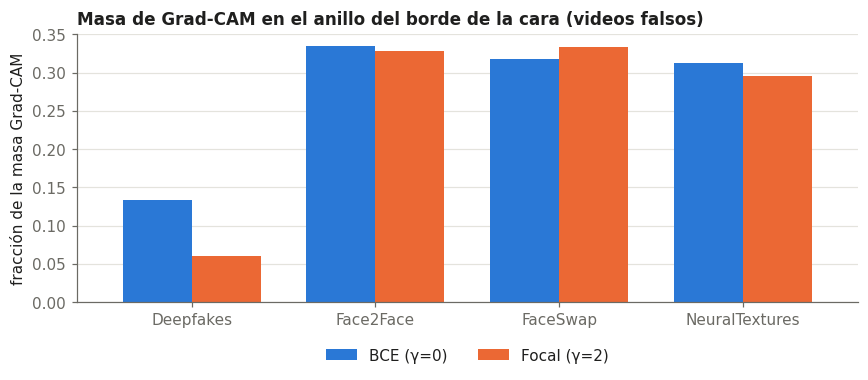

In [7]:
falsos = regiones[regiones.clase == "falso"].groupby(["test", "modelo"], observed=True)["masa_borde"].mean().unstack()
falsos = falsos.reindex([t for t in A.TEST_ORDER if t in falsos.index])
ax = falsos.plot.bar(figsize=(8, 3.6), color=S.SERIES[:falsos.shape[1]], width=0.75, rot=0)
ax.set_ylabel("fracción de la masa Grad-CAM"); ax.set_xlabel("")
ax.set_title("Masa de Grad-CAM en el anillo del borde de la cara (videos falsos)", loc="left"); ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout(); plt.savefig(OUT / "fig_gradcam_masa_borde.png", dpi=200); plt.show()

## 3. Contraste con la hipótesis
Resultados de la v2 (07/11/2026; `results/metrics/gradcam_masa_por_region.csv`), 2 frames por video de test, regiones concéntricas aproximadas.

| Predicción | Resultado | ¿Se cumplió? |
|---|---|---|
| Masa en el borde: Deepfakes bien detectados > FaceSwap no detectados | BCE: 0.126 (Deepfakes detectados) vs. 0.319 (FaceSwap no detectados) | No (al revés) |
| Focal no desplaza la masa hacia el interior | Falsos detectados en Deepfakes: interior 0.946 (Focal) vs. 0.866 (BCE) | No: Focal la concentra aún más en el interior |

**Lectura.** El patrón no es «borde de mezcla»: cuando el modelo dice *falso* (falsos detectados y también reales mal clasificados), la masa está en el **interior** de la cara (0.67–0.95 según manipulación y pérdida, con `area_50` ≈ 0.04–0.07, es decir, muy concentrada); cuando dice *real* (reales bien clasificados y falsos no detectados, incluido FaceSwap), la masa se va sobre todo **fuera** de la cara (0.31–0.62) y se dispersa (`area_50` ≈ 0.22–0.28). Una lectura compatible: el detector aprendió una evidencia del interior propia de Deepfakes; FaceSwap no la presenta y el modelo responde *real*. En la tabla de regiones no aparece ningún video FaceSwap acertado con Focal.

Límites: las regiones son concéntricas y aproximadas (no hay segmentación de la cara), es una sola semilla y Grad-CAM muestra correlación, no causalidad.